# Evaluation des NUTS-3-Versions-Crosswalks

Die Kreis-Datensätze liegen im Stand NUTS 2024 vor und werden über `mart_nuts_version_crosswalk` auf ältere Stände (2003 bis 2021) zurückgerechnet. Gewichtet wird mit der Gemeindebevölkerung (LAU). Hier werden fünf Varianten gegen eine aus den Daten abgeleitete Referenz verglichen. Sie werden in SQL/Python nachgebaut (lesend, nur temporäre Tabellen), die dbt-Modelle bleiben unberührt.

| Kürzel | Methode |
|---|---|
| A | Gemeinde ganz zum Kreis mit der größten Schnittfläche (alter dbt-Stand, mit Flächen-Fallback je Paar) |
| A0 | wie A, ohne Flächen-Fallback |
| B-xx | Bevölkerung anteilig nach Schnittfläche; ab `snap` Flächenanteil ganz in einen Kreis (`lau_nuts3_snap_share` 0,75 bis 1,0; neuer dbt-Stand, Default 0,95) |
| C | reine Flächengewichtung auf Kreisebene |
| D | Gemeinde ganz zum Kreis, der ihren `ST_PointOnSurface` enthält |

Voraussetzung: lokale PostGIS-DB mit den dbt-Modellen `stg_lau_population`, `stg_lau_geometry`, `int_lau_population_geo`, `mart_nuts_geometry_historized`, `stg_beschaeftigungsquote_gemeinden`, `stg_sgb_ii_quote_kreise`. Verbindung über `PG*`-Variablen. Die Geometrie-Verschneidungen werden als Parquet in `CW_EVAL_CACHE` zwischengespeichert (`CW_EVAL_REFRESH=1` erzwingt Neuberechnung).

In [3]:
import os
import tempfile
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import psycopg2

warnings.filterwarnings("ignore", message="pandas only supports SQLAlchemy connectable")
warnings.filterwarnings("ignore", category=DeprecationWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
try:
    display  # in Jupyter vorhanden
except NameError:  # Ausführung als Skript
    display = print
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)

PGHOST = os.environ.get("PGHOST", "localhost")
PGPORT = int(os.environ.get("PGPORT", "5432"))
PGDATABASE = os.environ.get("PGDATABASE", "soziooekonomische-daten")
PGUSER = os.environ.get("PGUSER", "sozio_data_compose_user")
PGPASSWORD = os.environ.get("PGPASSWORD", "local_dev_password")

CACHE = Path(os.environ.get("CW_EVAL_CACHE", Path(tempfile.gettempdir()) / "nuts3_crosswalk_eval"))
CACHE.mkdir(parents=True, exist_ok=True)
REFRESH = os.environ.get("CW_EVAL_REFRESH") == "1"
RESULTS = Path("results")  # relativ zu analysis/data-analysis/ (Arbeitsverzeichnis von nbconvert)

VERSIONS = [2003, 2006, 2010, 2013, 2016, 2021, 2024]
TARGETS = [2003, 2006, 2010, 2013, 2016, 2021]
SOURCE = 2024
FINE_YEAR = 2019      # feine Einheiten (Gemeindestand 2019, Bevölkerung 2019)
COARSE_YEAR = 2023    # grobe Einheiten = Gemeindestand, den die Produktion für Paare mit 2024 nutzt
CODE_YEAR = 2024      # Gemeindestand, dessen deklarierter NUTS-Code die Quellkreise (2024) liefert
AGS_VINTAGE = {2003: 2011, 2006: 2011, 2010: 2011, 2013: 2015}  # LAU-Geometriestand für die AGS-Wahrheit
TOL = 0.002          # max. unsicherer Anteil an der Kreisbevölkerung, damit ein Kreis als 'mit Wahrheit' zählt
CERTAIN = 0.97        # Anteil, ab dem eine Gemeinde eindeutig in einer Einheit liegt (Wahrheitskonstruktion)

conn = psycopg2.connect(host=PGHOST, port=PGPORT, dbname=PGDATABASE, user=PGUSER, password=PGPASSWORD)
conn.autocommit = True
print("Cache:", CACHE)

Cache: /tmp/nuts3_crosswalk_eval


## 1 Deklarierte NUTS-Codes in den LAU-Tabellen

Je Vintage steht in `loaded_data.lau_population` der NUTS-3-Code der Gemeinde. Geprüft wird, zu welchen NUTS-Versionen diese Codes passen.

In [4]:
declared = pd.read_sql(
    """
    with p as (
        select year, nuts_3_code, count(*) as n_lau, sum(population_count) as pop
        from transformed_data.stg_lau_population
        where gisco_id like 'DE%' and has_valid_population
        group by 1, 2
    ),
    nv as (
        select distinct year as version, nuts_id
        from transformed_data.stg_nuts_geometry
        where country_code = 'DE' and levl_code = 3
    )
    select p.year as vintage, v.version,
           count(*) filter (where nv.nuts_id is null) as codes_fehlend,
           sum(p.pop) filter (where nv.nuts_id is null) as einwohner_fehlend
    from p
    cross join (select distinct version from nv) v
    left join nv on nv.version = v.version and nv.nuts_id = p.nuts_3_code
    group by 1, 2
    order by 1, 2
    """,
    conn,
)
tab = declared.pivot(index="vintage", columns="version", values="codes_fehlend")
tab.columns = [f"fehlend in NUTS {c}" for c in tab.columns]
tab

,fehlend in NUTS 2003,fehlend in NUTS 2006,fehlend in NUTS 2010,fehlend in NUTS 2013,fehlend in NUTS 2016,fehlend in NUTS 2021,fehlend in NUTS 2024
vintage,,,,,,,
2018,54,40,9,3,0,0,7
2019,54,40,9,3,0,0,7
2020,54,40,9,3,0,0,7
2021,54,40,9,3,0,0,7
2022,54,40,9,3,0,0,6
2023,55,41,10,4,1,1,7
2024,61,47,16,10,7,7,1
2025,60,46,15,9,6,6,0


Die Vintages 2018 bis 2021 passen zu NUTS 2016/2021 (401 Codes), 2022/2023 zu NUTS 2021 mit Eisenach im Wartburgkreis (400 Codes), ab 2024 gilt NUTS 2024. Vor 2018 gibt es keine LAU-Bevölkerung. Eine deklarierte Referenz existiert daher nur für 2016/2021 und 2024. Für ältere Stände wird sie über die amtlichen Gemeindeschlüssel der LAU-Geometrien 2011 und 2015 gebildet (erste 5 Stellen = damaliger Kreis).

## 2 Validierungsdesign

Als feine Einheiten dienen die 11 087 Gemeinden im Stand 2019 mit ihrer Bevölkerung 2019. Sie liegen in den Gemeinden 2023, aus denen die Produktion ihre Gewichte bildet. Ihre Kreiszugehörigkeit im alten Stand liefert die Referenz:

* Zielstand 2016/2021: deklarierter `nuts_3_code` des Vintages 2019.
* Zielstand 2013 und älter: Verknüpfung mit den LAU-Einheiten 2015 bzw. 2011 über die Geometrie. Liegt eine feine Einheit zu mindestens 97 % in Gemeinden eines AGS-Kreises, ist ihr damaliger Kreis bekannt. Dieser wird dem NUTS-Kreis zugeordnet, in dem er zu mindestens 90 % liegt. Einheiten ohne eindeutigen Bezug gelten als unsicher. Ein Kreis hat nur dann eine Referenz, wenn die unsicheren Einwohner höchstens 0,2 % ausmachen können, sonst gibt es nur Schranken (`lower`/`upper`).
* Quelle (Stand 2024, Jahr 2019): Bevölkerung 2019 der feinen Einheiten, summiert nach dem 2024 deklarierten Kreis.
* Gewichte in zwei Varianten: isoliert (Bevölkerung 2019, misst nur den räumlichen Fehler) und produktiv (Bevölkerung 2023 wie in dbt).

Nicht auflösbar sind Gemeinden, die schon 2011 kreisübergreifend waren: Potsdam 2003, Dessau-Roßlau, die Kreise der Reform Sachsen-Anhalt 2007 (u. a. DEE12) und Sachsen 2008. Dort gibt es nur Schranken. Suhl und die Thüringer Fusionen 2019 bis 2023 sind dagegen validierbar.

In [6]:
def cached(name, sql_or_fn):
    """Parquet-Cache um eine Abfrage (str) oder Funktion."""
    path = CACHE / f"{name}.parquet"
    if path.exists() and not REFRESH:
        return pd.read_parquet(path)
    t0 = time.time()
    df = pd.read_sql(sql_or_fn, conn) if isinstance(sql_or_fn, str) else sql_or_fn()
    df.to_parquet(path, index=False)
    print(f"  {name}: {len(df)} Zeilen in {time.time() - t0:.1f}s berechnet")
    return df


def run(sql):
    with conn.cursor() as cur:
        cur.execute(sql)


t_start = time.time()
need_geo = REFRESH or not all(
    (CACHE / f"{n}.parquet").exists()
    for n in ["regions", "nuts_x", "units", "pieces", "pos", "fine", "ags_link", "ags_kreis", "triple"]
)
if need_geo:
    # Temporäre Tabellen (nur in dieser Session sichtbar)
    run(f"""
    drop table if exists nuts_v;
    create temp table nuts_v as
    select vy as version, g.nuts_id, g.region_name, ST_MakeValid(g.geometry_3035) as geom
    from (select distinct year as vy from transformed_data.stg_nuts_geometry) v
    join transformed_data.mart_nuts_geometry_historized g
      on  g.levl_code = 3 and g.country_code = 'DE' and g.has_valid_geometry
      and g.valid_from <= vy and (g.valid_to is null or g.valid_to >= vy);
    create index on nuts_v using gist (geom); analyze nuts_v;

    drop table if exists lau;
    create temp table lau as
    select g.year, g.gisco_id, g.population_count as pop, p.nuts_3_code as declared,
           ST_MakeValid(g.geometry_3035) as geom, ST_Area(g.geometry_3035) as area,
           ST_PointOnSurface(ST_MakeValid(g.geometry_3035)) as pos
    from transformed_data.int_lau_population_geo g
    left join transformed_data.stg_lau_population p on p.gisco_id = g.gisco_id and p.year = g.year
    where g.year in ({FINE_YEAR}, {COARSE_YEAR}, {CODE_YEAR});
    create index on lau using gist (geom); analyze lau;

    drop table if exists lau_old;
    create temp table lau_old as
    select year, gisco_id, substr(lau_id, 1, 5) as ags5, ST_MakeValid(geometry_3035) as geom,
           ST_Area(geometry_3035) as area
    from transformed_data.stg_lau_geometry
    where country_code = 'DE' and has_valid_geometry and year in ({",".join(map(str, sorted(set(AGS_VINTAGE.values()))))});
    create index on lau_old using gist (geom); analyze lau_old;
    """)

regions = cached("regions", "select version, nuts_id, region_name, ST_Area(geom) as area from nuts_v")

# NUTS x NUTS: Flächenanteil der Quellregion (2024) im Zielkreis (Methode C, Kandidatenpaare)
nuts_x = cached("nuts_x", f"""
    select s.nuts_id as source_nuts_id, t.version as target_version, t.nuts_id as target_nuts_id,
           ST_Area(ST_Intersection(s.geom, t.geom)) / ST_Area(s.geom) as area_fraction
    from nuts_v s join nuts_v t on ST_Intersects(s.geom, t.geom)
    where s.version = {SOURCE} and t.version <> {SOURCE}
""")

units = cached("units", "select year, gisco_id, pop, declared, area from lau")

# Gemeinde x Kreis je Version: Flächenanteil der Gemeinde (alle drei Gemeindestände)
pieces = cached("pieces", """
    select l.year, l.gisco_id, n.version, n.nuts_id,
           case when ST_Within(l.geom, n.geom) then 1.0
                else ST_Area(ST_Intersection(l.geom, n.geom)) / nullif(l.area, 0) end as area_share
    from lau l join nuts_v n on ST_Intersects(l.geom, n.geom)
""")

# Methode D: Kreis, der den Punkt auf der Gemeindefläche enthält
pos = cached("pos", """
    select l.year, l.gisco_id, n.version, n.nuts_id
    from lau l join nuts_v n on ST_Within(l.pos, n.geom)
""")

# Feine Einheiten (2019) -> umgebende grobe Einheit (2023) und Code-Einheit (2024)
fine = cached("fine", f"""
    select f.gisco_id, c.year as other_year, c.gisco_id as other_gisco_id, c.declared as other_declared,
           ST_Area(ST_Intersection(f.geom, c.geom)) / nullif(f.area, 0) as share
    from lau f join lau c on c.year in ({COARSE_YEAR}, {CODE_YEAR}) and ST_Intersects(f.geom, c.geom)
    where f.year = {FINE_YEAR}
""")

# Feine Einheiten (2019) -> LAU-Einheiten 2011/2015 (für den damaligen AGS-Kreis)
ags_link = cached("ags_link", f"""
    select f.gisco_id, o.year as ags_vintage, o.ags5,
           sum(ST_Area(ST_Intersection(f.geom, o.geom))) / max(f.area) as share
    from lau f join lau_old o on ST_Intersects(f.geom, o.geom)
    where f.year = {FINE_YEAR}
    group by 1, 2, 3
""")

# AGS-Kreis (Vereinigung der LAU-Einheiten) x NUTS-Kreis je Version
ags_kreis = cached("ags_kreis", """
    with k as (
        select year, ags5, sum(area) as k_area from lau_old group by 1, 2
    )
    select o.year as ags_vintage, o.ags5, n.version, n.nuts_id,
           sum(case when ST_Within(o.geom, n.geom) then o.area
                    else ST_Area(ST_Intersection(o.geom, n.geom)) end) / max(k.k_area) as share
    from lau_old o
    join k on k.year = o.year and k.ags5 = o.ags5
    join nuts_v n on ST_Intersects(o.geom, n.geom)
    group by 1, 2, 3, 4
""")

# Dreifach-Verschnitt grobe Gemeinde ∩ Quellkreis 2024 ∩ Zielkreis V (für Methode B,
# wenn die Gemeinde in beiden Ständen geteilt ist) - nur für Gemeinden mit
# mehreren Teilen im Stand 2024
triple = cached("triple", f"""
    with split24 as (
        select l.gisco_id
        from lau l join nuts_v n on n.version = {SOURCE} and ST_Intersects(l.geom, n.geom)
        where l.year = {COARSE_YEAR}
          and ST_Area(ST_Intersection(l.geom, n.geom)) > 0
          and not ST_Within(l.geom, n.geom)
        group by 1 having count(*) > 1
    ),
    sg as (
        select l.gisco_id, l.area, n.nuts_id as s, ST_Intersection(l.geom, n.geom) as g
        from lau l join split24 using (gisco_id) join nuts_v n
          on n.version = {SOURCE} and ST_Intersects(l.geom, n.geom)
        where l.year = {COARSE_YEAR}
    )
    select sg.gisco_id, t.version as target_version, sg.s as source_nuts_id, t.nuts_id as target_nuts_id,
           ST_Area(ST_Intersection(sg.g, t.geom)) / nullif(sg.area, 0) as share
    from sg join nuts_v t on t.version <> {SOURCE} and ST_Intersects(sg.g, t.geom)
""")
print(f"Geometrie-Basis fertig nach {time.time() - t_start:.0f}s;",
      {k: len(v) for k, v in dict(pieces=pieces, fine=fine, ags_link=ags_link, triple=triple).items()})

  regions: 2884 Zeilen in 0.2s berechnet
  nuts_x: 15052 Zeilen in 7.5s berechnet
  units: 33055 Zeilen in 0.1s berechnet
  pieces: 409056 Zeilen in 45.0s berechnet
  pos: 231354 Zeilen in 3.1s berechnet
  fine: 152363 Zeilen in 13.0s berechnet
  ags_link: 39332 Zeilen in 12.3s berechnet
  ags_kreis: 35416 Zeilen in 43.8s berechnet
  triple: 186535 Zeilen in 78.8s berechnet
Geometrie-Basis fertig nach 206s; {'pieces': 409056, 'fine': 152363, 'ags_link': 39332, 'triple': 186535}


## 3 Referenz und Quelle aufbauen

In [7]:
units = units[units.gisco_id.notna()]
pop = {y: units[units.year == y].set_index("gisco_id")["pop"].astype(float) for y in units.year.unique()}
declared_of = {y: units[units.year == y].set_index("gisco_id")["declared"] for y in units.year.unique()}
pieces = pieces[pieces.area_share > 0].copy()
region_name = regions.drop_duplicates("nuts_id", keep="last").set_index("nuts_id")["region_name"]


def best(df, key, by="share"):
    """Zeile mit dem größten Anteil je key, plus normierter Anteil (bezogen auf die abgedeckte Fläche)."""
    df = df.copy()
    df["share_norm"] = df[by] / df.groupby(key)[by].transform("sum")
    return df.sort_values(by, ascending=False).drop_duplicates(key)


# feine Einheit -> grobe Einheit 2023 / Code-Einheit 2024
f2c = best(fine[fine.other_year == COARSE_YEAR], "gisco_id").set_index("gisco_id")
f2k = best(fine[fine.other_year == CODE_YEAR], "gisco_id").set_index("gisco_id")
F = pd.DataFrame({"pop": pop[FINE_YEAR], "declared": declared_of[FINE_YEAR]})
F["coarse"] = f2c["other_gisco_id"]
F["nest_share"] = f2c["share_norm"]
F["code2024"] = f2k["other_declared"]
print(f"feine Einheiten: {len(F)}, Bevölkerung {F['pop'].sum():,.0f}; "
      f"nicht sauber eingebettet (<{CERTAIN:.0%}): {(F.nest_share < CERTAIN).sum()} "
      f"({F.loc[F.nest_share < CERTAIN, 'pop'].sum():,.0f} Einw.)")

# Quelle: Bevölkerung 2019 im Gebietsstand 2024
codes24 = set(regions.loc[regions.version == SOURCE, "nuts_id"])
src = F[F.code2024.isin(codes24)].groupby("code2024")["pop"].sum()
print(f"Quelle 2024: {len(src)} Kreise, {src.sum():,.0f} Einw. (nicht zuordenbar: {F.loc[~F.code2024.isin(codes24), 'pop'].sum():,.0f})")

# grobe Einheiten: Bevölkerung isoliert (2019, aus feinen Einheiten) bzw. produktiv (2023)
coarse_pop = {
    "isoliert": F.groupby("coarse")["pop"].sum(),
    "produktiv": pop[COARSE_YEAR],
}

# Gemeinden der Stände 2019 und 2023, die im jeweiligen Stand wirklich geteilt sind
fp = pieces[pieces.year == FINE_YEAR].copy()
fp["share_norm"] = fp.area_share / fp.groupby(["gisco_id", "version"]).area_share.transform("sum")


def truth_for(version):
    """Wahre Kreisbevölkerung 2019 im Stand `version` + Kennzeichnung, wo keine Wahrheit existiert."""
    names = set(regions.loc[regions.version == version, "nuts_id"])
    if version in (2016, 2021):
        k = F["declared"].where(F["declared"].isin(names))
    else:
        al = ags_link[ags_link.ags_vintage == AGS_VINTAGE[version]]
        al = best(al, "gisco_id").set_index("gisco_id")
        ak = ags_kreis[(ags_kreis.ags_vintage == AGS_VINTAGE[version]) & (ags_kreis.version == version)]
        ak = best(ak, "ags5")
        kmap = ak.loc[ak.share_norm >= 0.9].set_index("ags5")["nuts_id"]
        ags = al["ags5"].where(al["share_norm"] >= CERTAIN)
        k = ags.map(kmap).reindex(F.index)
    certain = k.notna()
    tr = F.loc[certain].groupby(k[certain])["pop"].sum()
    # unsichere feine Einheiten (kein eindeutiger damaliger Kreis): ihre Einwohner werden
    # nach Fläche auf die berührten Kreise verteilt; ist dieser Anteil > TOL der Kreis-
    # bevölkerung, gilt der Kreis als "ohne Wahrheit" (Schranken: lower/upper)
    unc = fp[(fp.version == version) & fp.gisco_id.isin(F.index[~certain]) & (fp.share_norm > 0.001)]
    unc = unc.assign(pop=unc.gisco_id.map(F["pop"]).astype(float))
    alloc = (unc["pop"] * unc.share_norm).groupby(unc.nuts_id).sum()
    touch = unc.groupby("nuts_id")["pop"].sum()
    out = pd.DataFrame(index=sorted(names))
    out["lower"] = tr.reindex(out.index).fillna(0.0).astype(float)
    out["truth"] = out["lower"] + alloc.reindex(out.index).fillna(0.0)
    out["upper"] = out["lower"] + touch.reindex(out.index).fillna(0.0)
    out["has_truth"] = (out["lower"] > 0) & (out["upper"] - out["lower"] <= TOL * out["lower"])
    out["version"] = version
    KMAP[version] = k.where(certain)
    return out


KMAP = {}  # feine Einheit -> Kreis im Stand V (nur eindeutige), für den Quotentest
truth = pd.concat([truth_for(v) for v in TARGETS]).rename_axis("nuts_id").reset_index()
cov = truth.groupby("version").agg(
    kreise=("nuts_id", "size"),
    mit_wahrheit=("has_truth", "sum"),
    einw_mit_wahrheit=("truth", lambda s: s[truth.loc[s.index, "has_truth"]].sum()),
)
cov["anteil_einw"] = (cov.einw_mit_wahrheit / src.sum()).round(3)
cov

feine Einheiten: 11087, Bevölkerung 83,019,213; nicht sauber eingebettet (<97%): 466 (665,842 Einw.)
Quelle 2024: 400 Kreise, 83,019,213 Einw. (nicht zuordenbar: 0)


,kreise,mit_wahrheit,einw_mit_wahrheit,anteil_einw
version,,,,
2003,439,316,6.151630e+07,0.741
2006,429,339,6.817634e+07,0.821
2010,412,370,7.586187e+07,0.914
2013,402,372,7.767279e+07,0.936
2016,401,401,8.301921e+07,1.000
2021,401,401,8.301921e+07,1.000


Die Referenz ist für 2016/2021 vollständig. Für 2013/2010 fehlen nur Kreise neben Einheiten ohne eindeutigen damaligen Kreis, für 2003/2006 zusätzlich die bis 2011 reformierten Kreise.

## 4 Methoden nachbauen

Je Methode entstehen Paargewichte *P(s, t)* (Einwohner der Quellregion *s* im Zielkreis *t*), daraus die normierten Anteile und die absoluten Gewichte, wie in `mart_nuts_version_crosswalk`.

In [8]:
cp = pieces[pieces.year == COARSE_YEAR].copy()
cp["share_norm"] = cp.area_share / cp.groupby(["gisco_id", "version"]).area_share.transform("sum")
cp["max_norm"] = cp.groupby(["gisco_id", "version"]).share_norm.transform("max")
cp = cp.sort_values(["gisco_id", "version", "area_share", "nuts_id"], ascending=[True, True, False, True])
cp["rn"] = cp.groupby(["gisco_id", "version"]).cumcount() + 1
cpos = pos[pos.year == COARSE_YEAR]
cand = nuts_x[nuts_x.area_fraction > 0.01]  # Kandidatenpaare wie int_nuts_spatial_crosswalk
trip = triple.copy()
trip["share"] = trip.share / trip.groupby(["gisco_id", "target_version"]).share.transform("sum")


def membership(version, method, snap=None):
    """(gisco_id, nuts_id, w) mit Σw = 1 je Gemeinde; Gemeindestand 2023."""
    p = cp[cp.version == version]
    if method in ("A", "A0"):
        m = p[p.rn == 1].assign(w=1.0)
    elif method == "D":
        m = cpos[cpos.version == version].drop_duplicates("gisco_id").assign(w=1.0)
        missing = p[(p.rn == 1) & ~p.gisco_id.isin(m.gisco_id)].assign(w=1.0)  # Punkt außerhalb aller Kreise
        m = pd.concat([m, missing])
    else:  # B
        snapped = p.max_norm >= snap
        m = pd.concat([p[snapped & (p.rn == 1)].assign(w=1.0), p[~snapped].assign(w=p.share_norm[~snapped])])
        m["split"] = ~(m.w == 1.0)
        return m[["gisco_id", "nuts_id", "w", "split"]]
    return m[["gisco_id", "nuts_id", "w"]].assign(split=False)


def pair_population(version, method, snap, cpop):
    s = membership(SOURCE, method, snap).rename(columns={"nuts_id": "source_nuts_id", "w": "ws", "split": "ss"})
    t = membership(version, method, snap).rename(columns={"nuts_id": "target_nuts_id", "w": "wt", "split": "st"})
    pr = s.merge(t, on="gisco_id")
    pr["pop"] = pr.gisco_id.map(cpop).fillna(0)
    pr["share"] = pr.ws * pr.wt
    both = pr.ss & pr.st
    if both.any():  # Gemeinde in beiden Ständen geteilt -> exakter Dreifach-Verschnitt
        tv = trip[trip.target_version == version][["gisco_id", "source_nuts_id", "target_nuts_id", "share"]]
        pb = pr[both].drop(columns="share").merge(tv, on=["gisco_id", "source_nuts_id", "target_nuts_id"], how="left")
        pb["share"] = pb.share.fillna(0)
        pr = pd.concat([pr[~both], pb])
    pr["P"] = pr["pop"] * pr["share"]
    return pr.groupby(["source_nuts_id", "target_nuts_id"])["P"].sum()


def crosswalk(version, method, snap=None, weights="isoliert"):
    """Normierte Gewichte + absolute Gewichte (Einwohner) je (Quelle 2024, Ziel V)."""
    c = cand[cand.target_version == version][["source_nuts_id", "target_nuts_id", "area_fraction"]].copy()
    cpop = coarse_pop[weights]
    srcpop = src.reindex(c.source_nuts_id).fillna(0).values
    if method == "C":
        c["basis"] = c.area_fraction
        c["absolute"] = c.area_fraction * srcpop
    else:
        P = pair_population(version, method, snap, cpop)
        c["P"] = P.reindex(pd.MultiIndex.from_frame(c[["source_nuts_id", "target_nuts_id"]])).values
        if method == "A":  # alter Stand: je Paar Flächenanteil statt Einwohner, falls keine Einwohner
            c["basis"] = c.P.fillna(c.area_fraction)
            c["absolute"] = c["basis"]
        else:  # neuer Stand: Einwohner; nur wenn die ganze Quellgruppe keine hat -> Fläche
            c["P"] = c.P.fillna(0)
            grp = c.groupby("source_nuts_id").P.transform("sum")
            c["basis"] = np.where(grp > 0, c.P, c.area_fraction)
            c["absolute"] = np.where(grp > 0, c.P, c.area_fraction * srcpop)
    c["population_weight"] = c.basis / c.groupby("source_nuts_id").basis.transform("sum")
    return c


def transfer_count(c, values):
    v = values.reindex(c.source_nuts_id).fillna(0).values
    return (c.population_weight * v).groupby(c.target_nuts_id).sum()


def transfer_avg(c, values):
    v = values.reindex(c.source_nuts_id).values
    ok = ~np.isnan(v) & (c.absolute.values > 0)
    num = (v[ok] * c.absolute.values[ok])
    return pd.Series(num, index=c.target_nuts_id.values[ok]).groupby(level=0).sum() / \
        pd.Series(c.absolute.values[ok], index=c.target_nuts_id.values[ok]).groupby(level=0).sum()


METHODS = {"A": ("A", None), "A0": ("A0", None), "B-0.75": ("B", 0.75), "B-0.90": ("B", 0.90), "B-0.95": ("B", 0.95),
           "B-0.99": ("B", 0.99), "B-1.00": ("B", 1.0), "C": ("C", None), "D": ("D", None)}
t0 = time.time()
CW = {(v, m, w): crosswalk(v, *METHODS[m], weights=w)
      for v in TARGETS for m in METHODS for w in ("isoliert", "produktiv")}
print(f"{len(CW)} Crosswalks in {time.time() - t0:.0f}s gebaut")

# Konsistenzcheck: Summe Deutschland bleibt erhalten
chk = pd.DataFrame([{"version": v, "methode": m, "gewichte": w,
                     "summe_ziel_minus_quelle": transfer_count(c, src).sum() - src.sum()}
                    for (v, m, w), c in CW.items()])
print("max. Abweichung der Deutschland-Summe:", f"{chk.summe_ziel_minus_quelle.abs().max():.3f} Einw.")

108 Crosswalks in 3s gebaut
max. Abweichung der Deutschland-Summe: 0.000 Einw.


## 5 Übertragene Kreisbevölkerung gegen die Referenz

Ausgewertet werden die "betroffenen" Kreise: solche mit echter Gebietsänderung gegenüber 2024 (Abweichung über 0,5 % oder Code existiert 2024 nicht) oder mit Methodenunterschied über 0,5 %. Bei den übrigen sind alle Methoden praktisch fehlerfrei.

In [9]:
rows = []
for (v, m, w), c in CW.items():
    est = transfer_count(c, src)
    rows.append(pd.DataFrame({"version": v, "methode": m, "gewichte": w, "nuts_id": est.index, "est": est.values}))
est_all = pd.concat(rows)
ev = est_all.merge(truth, on=["version", "nuts_id"], how="left")
ev["region_name"] = ev.nuts_id.map(region_name)
ev["err_pct"] = 100 * (ev.est - ev.truth) / ev.truth
spread = ev[ev.gewichte == "isoliert"].groupby(["version", "nuts_id"]).est.agg(lambda s: (s.max() - s.min()) / max(s.mean(), 1))
same_code = truth.assign(src_same=truth.nuts_id.map(src)).set_index(["version", "nuts_id"])
changed = (same_code.src_same.isna()) | ((same_code.src_same - same_code.truth).abs() > 0.005 * same_code.truth)
affected = (changed | (spread.reindex(changed.index).fillna(0) > 0.005)).rename("betroffen")
ev = ev.merge(affected.reset_index(), on=["version", "nuts_id"], how="left")
evt = ev[ev.has_truth == True].copy()


def metrics(g):
    e = g.err_pct
    return pd.Series({
        "n": len(g), "MAPE_%": e.abs().mean(), "MdAPE_%": e.abs().median(), "Bias_%": e.mean(),
        "P95_APE_%": e.abs().quantile(0.95), "max_APE_%": e.abs().max(),
        "WAPE_%": 100 * (g.est - g.truth).abs().sum() / g.truth.sum(),
        "anteil_>1%": (e.abs() > 1).mean(), "anteil_>5%": (e.abs() > 5).mean(),
    })


order = list(METHODS)
summary_all = evt.groupby(["gewichte", "methode"]).apply(metrics).round(3)
summary_aff = evt[evt.betroffen].groupby(["gewichte", "methode"]).apply(metrics).round(3)
print("Alle Kreise mit Wahrheit (alle Zielstände zusammen):")
display(summary_all.loc["isoliert"].reindex(order))
print("Nur betroffene Kreise:")
display(summary_aff.loc["isoliert"].reindex(order))
print("Produktive Gewichte (Bevölkerung 2023), betroffene Kreise:")
display(summary_aff.loc["produktiv"].reindex(order))

Alle Kreise mit Wahrheit (alle Zielstände zusammen):


,n,MAPE_%,MdAPE_%,Bias_%,P95_APE_%,max_APE_%,WAPE_%,anteil_>1%,anteil_>5%
methode,,,,,,,,,
A,2199.0,0.055,0.0,0.016,0.000,6.085,0.022,0.017,0.003
A0,2199.0,0.055,0.0,0.016,0.000,6.086,0.022,0.017,0.003
B-0.75,2199.0,0.102,0.0,-0.045,0.000,26.297,0.030,0.011,0.005
B-0.90,2199.0,0.105,0.0,-0.045,0.000,26.297,0.033,0.014,0.005
B-0.95,2199.0,0.149,0.0,-0.046,0.001,26.297,0.052,0.022,0.010
B-0.99,2199.0,0.618,0.0,-0.171,2.896,26.297,0.385,0.219,0.011
B-1.00,2199.0,0.606,0.0,-0.167,2.813,26.363,0.376,0.211,0.011
C,2199.0,1.935,0.0,-0.331,3.699,95.452,0.836,0.239,0.038
D,2199.0,0.052,0.0,0.016,0.000,6.086,0.020,0.017,0.003


Nur betroffene Kreise:


,n,MAPE_%,MdAPE_%,Bias_%,P95_APE_%,max_APE_%,WAPE_%,anteil_>1%,anteil_>5%
methode,,,,,,,,,
A,648.0,0.186,0.000,0.053,1.949,6.085,0.094,0.057,0.009
A0,648.0,0.186,0.000,0.053,1.950,6.086,0.094,0.057,0.009
B-0.75,648.0,0.345,0.000,-0.153,0.664,26.297,0.129,0.039,0.019
B-0.90,648.0,0.355,0.000,-0.153,0.893,26.297,0.141,0.048,0.019
B-0.95,648.0,0.506,0.000,-0.155,1.337,26.297,0.222,0.076,0.034
B-0.99,648.0,2.082,1.499,-0.595,4.478,26.297,1.647,0.744,0.039
B-1.00,648.0,2.040,1.460,-0.583,4.456,26.363,1.609,0.718,0.037
C,648.0,6.549,1.744,-1.140,34.948,95.452,3.613,0.812,0.128
D,648.0,0.175,0.000,0.053,1.950,6.086,0.085,0.057,0.009


Produktive Gewichte (Bevölkerung 2023), betroffene Kreise:


,n,MAPE_%,MdAPE_%,Bias_%,P95_APE_%,max_APE_%,WAPE_%,anteil_>1%,anteil_>5%
methode,,,,,,,,,
A,648.0,0.255,0.000,0.059,1.949,6.085,0.125,0.079,0.009
A0,648.0,0.255,0.000,0.059,1.950,6.086,0.125,0.079,0.009
B-0.75,648.0,0.414,0.000,-0.148,1.270,26.297,0.161,0.069,0.019
B-0.90,648.0,0.424,0.000,-0.148,1.284,26.297,0.173,0.079,0.019
B-0.95,648.0,0.573,0.000,-0.150,1.694,26.297,0.253,0.103,0.034
B-0.99,648.0,2.111,1.499,-0.590,4.478,26.297,1.665,0.742,0.039
B-1.00,648.0,2.072,1.461,-0.578,4.456,26.361,1.628,0.728,0.037
C,648.0,6.549,1.744,-1.140,34.948,95.452,3.613,0.812,0.128
D,648.0,0.232,0.000,0.059,1.694,6.086,0.108,0.079,0.009


### MAPE und Bias je Zielstand (betroffene Kreise, isolierte Gewichte)

MAPE_%                                                      Bias_%                                                           n
methode      A    A0 B-0.75 B-0.90 B-0.95 B-0.99 B-1.00     C     D      A    A0 B-0.75 B-0.90 B-0.95 B-0.99 B-1.00     C     D Kreise
version                                                                                                                               
2003      0.15  0.15   0.27   0.29   0.66   2.04   2.00  8.26  0.15   0.04  0.04  -0.12  -0.12   0.03  -0.51  -0.49 -1.23  0.04    136
2006      0.14  0.14   0.27   0.28   0.34   1.94   1.89  8.04  0.13   0.04  0.04  -0.12  -0.12  -0.14  -0.49  -0.48 -1.15  0.04    137
2010      0.13  0.13   0.24   0.24   0.42   2.46   2.41  7.54  0.12   0.04  0.04  -0.10  -0.10  -0.18  -0.60  -0.58 -1.11  0.03    165
2013      0.16  0.16   0.32   0.34   0.41   2.05   2.00  3.40  0.16   0.04  0.04  -0.15  -0.15  -0.18  -0.71  -0.70 -0.59  0.04    124
2016      0.45  0.45   0.82   0.82   0.82   1.70   1.68  4.10  0.42   0.14  0.14  -0.38  -0.38  -0.38  -0.72  -0.73 -1.84  0.14     43
2021      0.45  0.45   0.82   0.82   0.82   1.70   1.68  4.10  0.42   0.14  0.14  -0.38  -0.38  -0.38  -0.72  -0.73 -1.84  0.14     43

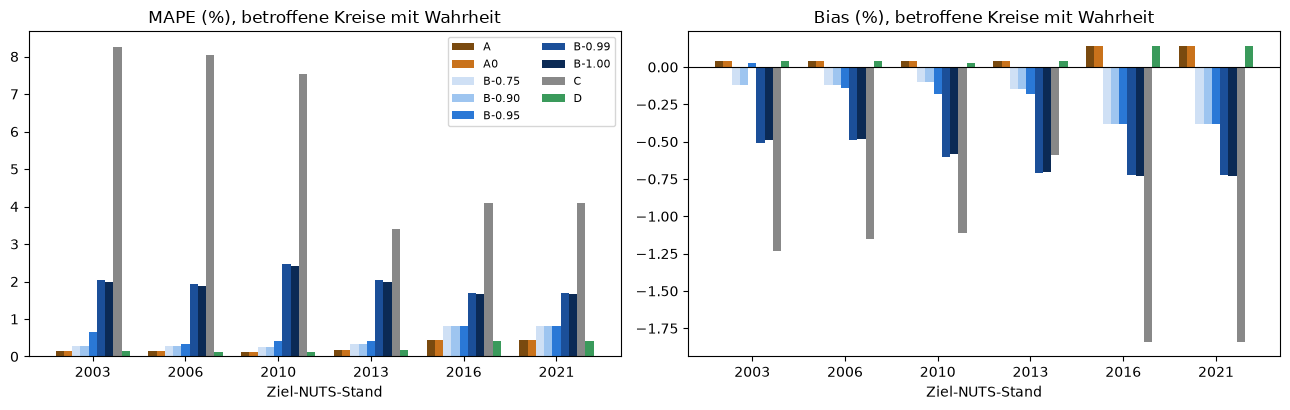

In [10]:
per_v = evt[evt.betroffen & (evt.gewichte == "isoliert")].groupby(["version", "methode"]).apply(metrics)
mape_v = per_v["MAPE_%"].unstack("methode")[order].round(2)
bias_v = per_v["Bias_%"].unstack("methode")[order].round(2)
n_v = per_v["n"].unstack("methode")[["A"]].astype(int).rename(columns={"A": "Kreise"})
display(pd.concat({"MAPE_%": mape_v, "Bias_%": bias_v, "n": n_v}, axis=1))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
x = np.arange(len(TARGETS))
colors = {"A": "#7a4a0f", "A0": "#c9721b", "B-0.75": "#cfe0f5", "B-0.90": "#9ec5f0", "B-0.95": "#2a78d6", "B-0.99": "#1b4f99",
          "B-1.00": "#0b2a55", "C": "#888888", "D": "#3a9a5b"}
wdt = 0.8 / len(order)
for i, m in enumerate(order):
    axes[0].bar(x + i * wdt, mape_v[m].reindex(TARGETS), wdt, label=m, color=colors[m])
    axes[1].bar(x + i * wdt, bias_v[m].reindex(TARGETS), wdt, label=m, color=colors[m])
for ax, t in zip(axes, ["MAPE (%)", "Bias (%)"]):
    ax.set_xticks(x + 0.4 - wdt / 2, [str(v) for v in TARGETS])
    ax.set_title(f"{t}, betroffene Kreise mit Wahrheit")
    ax.set_xlabel("Ziel-NUTS-Stand")
axes[1].axhline(0, color="black", linewidth=0.8)
axes[0].legend(fontsize=8, ncol=2)
fig.tight_layout()
plt.show()

### Fehlerverteilung (betroffene Kreise, isolierte Gewichte)

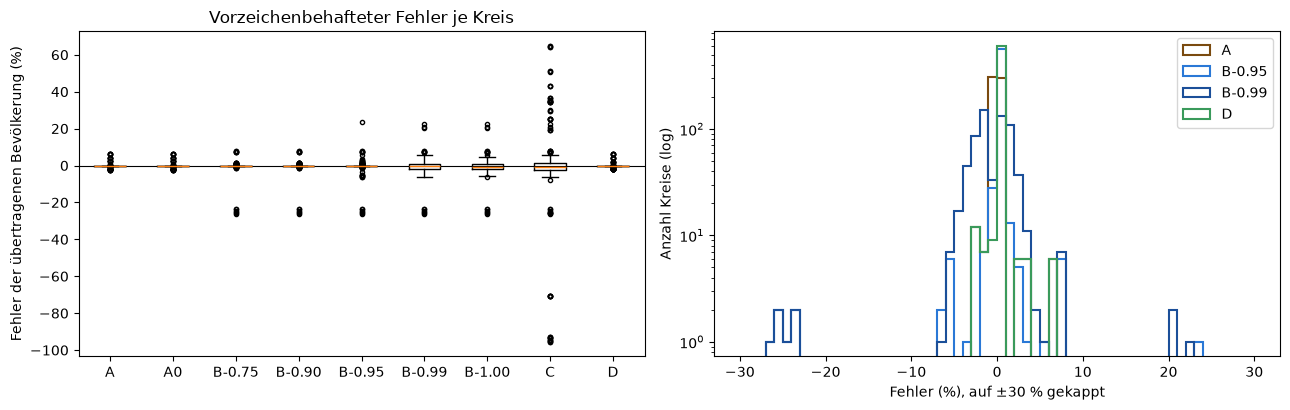

In [11]:
d = evt[evt.betroffen & (evt.gewichte == "isoliert")]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
axes[0].boxplot([d.loc[d.methode == m, "err_pct"] for m in order], tick_labels=order, showfliers=True,
                flierprops=dict(markersize=3))
axes[0].axhline(0, color="black", linewidth=0.8)
axes[0].set_ylabel("Fehler der übertragenen Bevölkerung (%)")
axes[0].set_title("Vorzeichenbehafteter Fehler je Kreis")
bins = np.linspace(-30, 30, 61)
for m in ["A", "B-0.95", "B-0.99", "D"]:
    axes[1].hist(d.loc[d.methode == m, "err_pct"].clip(-30, 30), bins=bins, histtype="step", linewidth=1.5,
                 label=m, color=colors[m])
axes[1].set_yscale("log")
axes[1].set_xlabel("Fehler (%), auf ±30 % gekappt")
axes[1].set_ylabel("Anzahl Kreise (log)")
axes[1].legend()
fig.tight_layout()
plt.show()

### Die 15 größten Abweichungen je Methode (isolierte Gewichte)

Je Kreis nur der schlechteste Zielstand.

In [12]:
worst = (evt[evt.gewichte == "isoliert"].assign(ape=lambda x: x.err_pct.abs())
         .sort_values("ape", ascending=False).drop_duplicates(["methode", "nuts_id"])
         .groupby("methode").head(15))
worst = worst.assign(methode=pd.Categorical(worst.methode, order)).sort_values(["methode", "ape"], ascending=[True, False])
with pd.option_context("display.max_rows", 200):
    display(worst[["methode", "version", "nuts_id", "region_name", "truth", "est", "err_pct"]]
            .round({"truth": 0, "est": 0, "err_pct": 1}).reset_index(drop=True))

,methode,version,nuts_id,region_name,truth,est,err_pct
0,A,2021,DEG04,"Suhl, Kreisfreie Stadt",34835.0,36955.0,6.1
1,A,2016,DEG0H,Sonneberg,56196.0,58410.0,3.9
2,A,2013,DEG0B,Schmalkalden-Meiningen,122347.0,125646.0,2.7
3,A,2016,DEG0P,Wartburgkreis,123025.0,119726.0,-2.7
4,A,2016,DEG0I,Saalfeld-Rudolstadt,106356.0,104142.0,-2.1
5,A,2003,DEG0F,Ilm-Kreis,108742.0,106622.0,-1.9
6,A,2013,DEB19,Rhein-Hunsrück-Kreis,102926.0,101896.0,-1.0
7,A,2010,DEB22,Bernkastel-Wittlich,113273.0,112262.0,-0.9
8,A,2010,DEB25,Trier-Saarburg,147934.0,148945.0,0.7
9,A,2013,DE300,Berlin,3645644.0,3644826.0,-0.0


### Sensitivität von `lau_nuts3_snap_share`

Anzahl Kreise mit Fehler über 1 % bzw. 5 % (betroffene Kreise, isolierte Gewichte).

In [13]:
sens = (d.assign(gt1=d.err_pct.abs() > 1, gt5=d.err_pct.abs() > 5)
        .groupby(["methode", "version"])[["gt1", "gt5"]].sum().unstack("version"))
display(sens.reindex(order))

gt1                           gt5                         
version 2003 2006 2010 2013 2016 2021 2003 2006 2010 2013 2016 2021
methode                                                            
A          6    6    6    7    6    6    1    1    1    1    1    1
A0         6    6    6    7    6    6    1    1    1    1    1    1
B-0.75     3    4    4    6    4    4    2    2    2    2    2    2
B-0.90     5    6    4    8    4    4    2    2    2    2    2    2
B-0.95    12    8   11   10    4    4    6    3    6    3    2    2
B-0.99    96   99  132  105   25   25    6    4    8    3    2    2
B-1.00    94   97  130  104   20   20    6    4    7    3    2    2
C        108  108  143  109   29   29   24   21   24    6    4    4
D          6    6    6    7    6    6    1    1    1    1    1    1

## 6 Beispiele

Bevölkerung 2019 im alten Kreis nach Methode (produktive Gewichte). `truth` ist nur bei `has_truth` belastbar, sonst gelten `lower`/`upper`.

In [14]:
EXAMPLES = [(2003, "DE423", "Potsdam (Grenzen vor Eingemeindung 2003)"), (2003, "DE428", "Potsdam-Mittelmark"),
            (2003, "DEE11", "Dessau"), (2003, "DEE12", "Anhalt-Zerbst"),
            (2003, "DEG04", "Suhl"), (2021, "DEG04", "Suhl (vor Eingemeindungen 2019)"),
            (2021, "DEG0N", "Eisenach"), (2013, "DE919", "Osterode am Harz"),
            (2003, "DE502", "Bremerhaven"), (2003, "DE932", "Cuxhaven")]
show = ["A", "B-0.75", "B-0.90", "B-0.95", "B-0.99", "C", "D"]
ex = ev[ev.gewichte == "produktiv"].pivot_table(index=["version", "nuts_id"], columns="methode", values="est")
tt = truth.set_index(["version", "nuts_id"])
ex_tab = pd.DataFrame([{
    "fall": label, "version": v, "nuts_id": n,
    "lower": tt.loc[(v, n), "lower"], "upper": tt.loc[(v, n), "upper"],
    "has_truth": tt.loc[(v, n), "has_truth"],
    **{m: ex.loc[(v, n), m] for m in show},
} for v, n, label in EXAMPLES]).round(0)
display(ex_tab)

# Ausgewählte Paargewichte (Anteil der Quellregion 2024, der im Zielkreis landet)
PAIRS = [(2003, "DE404", "DE428", "Potsdam 2024 -> Potsdam-Mittelmark 2003"),
         (2003, "DE502", "DE932", "Bremerhaven 2024 -> Cuxhaven 2003"),
         (2003, "DEE01", "DEE12", "Dessau-Roßlau 2024 -> Anhalt-Zerbst 2003"),
         (2021, "DEG0S", "DEG0B", "Suhl 2024 -> Schmalkalden-Meiningen 2021")]
pw = pd.DataFrame([{"paar": label, **{m: CW[(v, m, "produktiv")].set_index(["source_nuts_id", "target_nuts_id"])
                                      .population_weight.get((s, t), 0.0) for m in show}}
                   for v, s, t, label in PAIRS]).set_index("paar").round(3)
display(pw)

# Bremerhaven: Wie liegt die Gemeinde in der NUTS-Geometrie 2003?
bhv = cp[(cp.gisco_id == "DE_04012000") & (cp.version.isin([2003, 2006, 2010, 2024]))]
display(bhv[["version", "nuts_id", "area_share"]].round(3))

,fall,version,nuts_id,lower,upper,has_truth,A,B-0.75,B-0.90,B-0.95,B-0.99,C,D
0,Potsdam (Grenzen vor Eingemeindung 2003),2003,DE423,0.0,178089.0,False,178089.0,103494.0,103494.0,103494.0,103494.0,103481.0,178089.0
1,Potsdam-Mittelmark,2003,DE428,214664.0,564098.0,False,214665.0,289259.0,297034.0,297034.0,297044.0,297072.0,214664.0
2,Dessau,2003,DEE11,0.0,118817.0,False,81237.0,48850.0,48850.0,48850.0,48850.0,48869.0,81237.0
3,Anhalt-Zerbst,2003,DEE12,0.0,240511.0,False,41741.0,83251.0,83258.0,83258.0,85325.0,125188.0,41741.0
4,Suhl,2003,DEG04,34835.0,34835.0,True,36955.0,26301.0,26301.0,26301.0,26301.0,26278.0,36955.0
5,Suhl (vor Eingemeindungen 2019),2021,DEG04,34835.0,34835.0,True,36955.0,26609.0,26609.0,26609.0,26609.0,26605.0,36955.0
6,Eisenach,2021,DEG0N,42370.0,42370.0,True,43088.0,43088.0,43088.0,43088.0,42718.0,12430.0,43088.0
7,Osterode am Harz,2013,DE919,72148.0,72148.0,True,71653.0,71653.0,71653.0,71541.0,71577.0,118546.0,71653.0
8,Bremerhaven,2003,DE502,0.0,113634.0,False,113634.0,113634.0,88087.0,88087.0,88087.0,87559.0,113634.0
9,Cuxhaven,2003,DE932,198213.0,311847.0,False,198213.0,198213.0,221312.0,221312.0,221312.0,221511.0,198213.0


,A,B-0.75,B-0.90,B-0.95,B-0.99,C,D
paar,,,,,,,
Potsdam 2024 -> Potsdam-Mittelmark 2003,0.0,0.419,0.419,0.419,0.419,0.419,0.0
Bremerhaven 2024 -> Cuxhaven 2003,0.0,0.000,0.203,0.203,0.203,0.205,0.0
Dessau-Roßlau 2024 -> Anhalt-Zerbst 2003,0.0,0.399,0.399,0.399,0.399,0.398,0.0
Suhl 2024 -> Schmalkalden-Meiningen 2021,0.0,0.000,0.000,0.000,0.000,0.000,0.0


,version,nuts_id,area_share
147672,2003,DE502,0.775
206817,2003,DE932,0.203
147378,2003,DE501,0.022
227150,2003,DE94G,0.000
147693,2006,DE502,0.789
206970,2006,DE932,0.196
147420,2006,DE501,0.002
147705,2010,DE502,0.958
207122,2010,DE932,0.023
147462,2010,DE501,0.004


## 7 Anteilswerte (gewichtetes Mittel)

### 7a Synthetischer Quotentest

Die Beschäftigungsquote 2019 (Gemeindeebene) wird innerhalb einer Gemeinde als konstant angenommen und mit der Bevölkerung der feinen Einheiten gewichtet. So ist die "wahre" Quote der alten Kreise bekannt. Die Kreisquote 2024 wird wie in `mart_nuts3_sociodata_harmonized` zurückgerechnet, der Fehler in Prozentpunkten gemessen.

In [15]:
q = pd.read_sql("""
    select 'DE_' || geodata_id_lau as gisco_id, beschaeftigungsquote_prozent::float as q
    from transformed_data.stg_beschaeftigungsquote_gemeinden
    where year = 2019 and has_valid_value
""", conn).drop_duplicates("gisco_id").set_index("gisco_id")["q"]
F["q"] = f2k["other_gisco_id"].map(q)
Fq = F[F.q.notna()]
src_q = (Fq.q * Fq["pop"]).groupby(Fq.code2024).sum() / Fq["pop"].groupby(Fq.code2024).sum()
qrows = []
for v in TARGETS:
    k = KMAP[v].reindex(Fq.index)
    ok = k.notna()
    tq = (Fq.q[ok] * Fq["pop"][ok]).groupby(k[ok]).sum() / Fq["pop"][ok].groupby(k[ok]).sum()
    for m in order:
        for w in ("isoliert", "produktiv"):
            eq = transfer_avg(CW[(v, m, w)], src_q)
            qrows.append(pd.DataFrame({"version": v, "methode": m, "gewichte": w, "nuts_id": eq.index,
                                       "est": eq.values, "truth": tq.reindex(eq.index).values}))
qev = pd.concat(qrows).merge(truth[["version", "nuts_id", "has_truth"]], on=["version", "nuts_id"])
qev = qev.merge(affected.reset_index(), on=["version", "nuts_id"], how="left")
qev = qev[qev.has_truth & qev.truth.notna()]
qev["err_pp"] = qev.est - qev.truth
qsum = (qev[qev.betroffen].groupby(["gewichte", "methode"]).err_pp
        .agg(MAE_pp=lambda e: e.abs().mean(), Bias_pp="mean", P95_pp=lambda e: e.abs().quantile(0.95),
             max_pp=lambda e: e.abs().max(), n="size"))
display(qsum.round(3).unstack("gewichte").reindex(order))

MAE_pp            Bias_pp             P95_pp             max_pp                  n          
gewichte isoliert produktiv isoliert produktiv isoliert produktiv isoliert produktiv isoliert produktiv
methode                                                                                                
A           0.164     0.164   -0.009    -0.009    0.829     0.826    5.283     5.283      648       648
A0          0.164     0.164   -0.009    -0.009    0.829     0.826    5.283     5.283      648       648
B-0.75      0.164     0.164   -0.007    -0.007    0.829     0.826    5.283     5.283      648       648
B-0.90      0.164     0.164   -0.007    -0.007    0.829     0.826    5.283     5.283      648       648
B-0.95      0.165     0.165   -0.008    -0.008    0.829     0.826    5.283     5.283      648       648
B-0.99      0.186     0.186   -0.027    -0.027    0.830     0.827    5.283     5.283      648       648
B-1.00      0.186     0.186   -0.027    -0.027    0.830     0.827    5.283     5.283      648       648
C           0.187     0.187   -0.027    -0.027    0.718     0.718    5.283     5.283      648       648
D           0.163     0.163   -0.008    -0.008    0.829     0.826    5.283     5.283      648       648

### 7b `sgb_ii_quote` 2019 auf NUTS 2003

Reale Daten ohne Referenz (Kreis-Datensätze liegen nur im Stand 2024 vor). Gezeigt wird der Unterschied der Methoden zu A in Prozentpunkten.

In [16]:
sgb = pd.read_sql("""
    select geodata_id_nuts as nuts_id, sgb_ii_quote_prozent as q
    from transformed_data.stg_sgb_ii_quote_kreise where year = 2019 and has_valid_value
""", conn).drop_duplicates("nuts_id").set_index("nuts_id")["q"]
sg = pd.DataFrame({m: transfer_avg(CW[(2003, m, "produktiv")], sgb) for m in show})
diff = sg[show[1:]].sub(sg["A"], axis=0)
display(diff.abs().describe(percentiles=[0.5, 0.9, 0.99]).round(3))
top = diff["B-0.95"].abs().sort_values(ascending=False).head(10).index
display(sg.loc[top].assign(region=lambda x: x.index.map(region_name)).round(2))

,B-0.75,B-0.90,B-0.95,B-0.99,C,D
count,439.000,439.000,439.000,439.000,439.000,439.000
mean,0.005,0.010,0.013,0.024,0.025,0.000
std,0.069,0.107,0.114,0.121,0.121,0.006
min,0.000,0.000,0.000,0.000,0.000,0.000
50%,0.000,0.000,0.000,0.000,0.000,0.000
90%,0.000,0.000,0.000,0.045,0.049,0.000
99%,0.042,0.087,0.440,0.573,0.535,0.000
max,1.209,1.464,1.464,1.469,1.470,0.095


,A,B-0.75,B-0.90,B-0.95,B-0.99,C,D,region
DE428,3.78,4.99,5.24,5.24,5.25,5.25,3.78,Potsdam-Mittelmark
DE932,7.73,7.73,9.14,9.14,9.14,9.15,7.73,Cuxhaven
DEE12,10.51,11.30,11.30,11.30,11.27,11.08,10.51,Anhalt-Zerbst
DE255,4.86,4.86,4.86,5.65,5.67,5.67,4.86,"Schwabach, Kreisfreie Stadt"
DE429,8.46,8.46,8.97,8.97,8.97,8.97,8.46,Spree-Neiße
DE259,2.75,2.75,2.75,3.07,3.08,3.09,2.75,Nürnberger Land
DE237,2.67,2.67,2.67,2.83,2.83,2.83,2.67,Neustadt a. d. Waldnaab
DEG0F,7.50,7.40,7.40,7.40,7.40,7.40,7.50,Ilm-Kreis
DE247,3.51,3.51,3.51,3.61,3.61,3.61,3.51,"Coburg, Landkreis"
DEG09,8.96,8.90,8.90,8.90,8.90,8.83,8.96,Unstrut-Hainich-Kreis


Beim gewichteten Mittel werden Gewichtsfehler stark gedämpft: Im Quotentest sind alle Methoden außer B-0.99, B-1.00 und C gleichauf. Der Maximalfehler von etwa 5 pp ist bei allen gleich, weil später eingemeindete Städte (Stralsund, Wismar) die Quote des Großkreises erhalten. Im realen Vergleich unterscheiden sich A und B-0.95 bei 99 % der 2003er-Kreise um weniger als 0,5 pp, die größten Unterschiede (bis etwa 1,5 pp) liegen bei Potsdam-Mittelmark, Cuxhaven/Bremerhaven, Anhalt-Zerbst und Schwabach.

In [17]:
RESULTS.mkdir(exist_ok=True)
out = pd.concat([
    evt[evt.betroffen].groupby(["gewichte", "version", "methode"]).apply(metrics).reset_index().assign(kreise="betroffen"),
    evt.groupby(["gewichte", "version", "methode"]).apply(metrics).reset_index().assign(kreise="alle_mit_wahrheit"),
])
out.round(4).to_csv(RESULTS / "nuts3_crosswalk_eval_summary.csv", index=False)
ex_tab.to_csv(RESULTS / "nuts3_crosswalk_eval_examples.csv", index=False)
print("geschrieben:", RESULTS / "nuts3_crosswalk_eval_summary.csv", RESULTS / "nuts3_crosswalk_eval_examples.csv")
conn.close()
print(f"Gesamtlaufzeit: {time.time() - t_start:.0f}s (Geometrie aus Cache: {not need_geo})")

geschrieben: results/nuts3_crosswalk_eval_summary.csv results/nuts3_crosswalk_eval_examples.csv
Gesamtlaufzeit: 212s (Geometrie aus Cache: False)
